# 18 — Error diagnosis and calibration

The experiment is executed locally through `diagnose_and_calibrate.py`. These cells inspect its saved results. See the frozen plan for chronology and adoption criteria.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'blackrock_data').exists())
out = root / 'outputs/experiments/18_error_diagnosis_calibration'

,method,development_rmse_log,development_wape,development_bias,development_abs_bias,confirmation_rmse_log,confirmation_wape,confirmation_bias,passes_adoption_gate,log_rmse_change,wape_change,paired_daily_wape_ci_upper
0,global_log_shift,0.469210,0.355280,-0.133652,0.133652,0.431432,0.331520,-0.075858,False,-0.000204,0.000762,0.001643
1,global_share_ratio,0.492922,0.390694,0.011574,0.011574,0.461918,0.374769,0.059907,False,0.023508,0.036175,0.050091
2,global_smearing,0.556872,0.476308,0.165985,0.165985,0.459936,0.372191,0.054030,False,0.087458,0.121790,0.153889
3,shrunk_decile_ratio,0.504742,0.390754,0.011616,0.011616,0.458935,0.376178,0.062655,False,0.035328,0.036235,0.050232
4,uncalibrated,0.469414,0.354518,-0.144042,0.144042,0.430646,0.329428,-0.088980,False,NaN,NaN,NaN


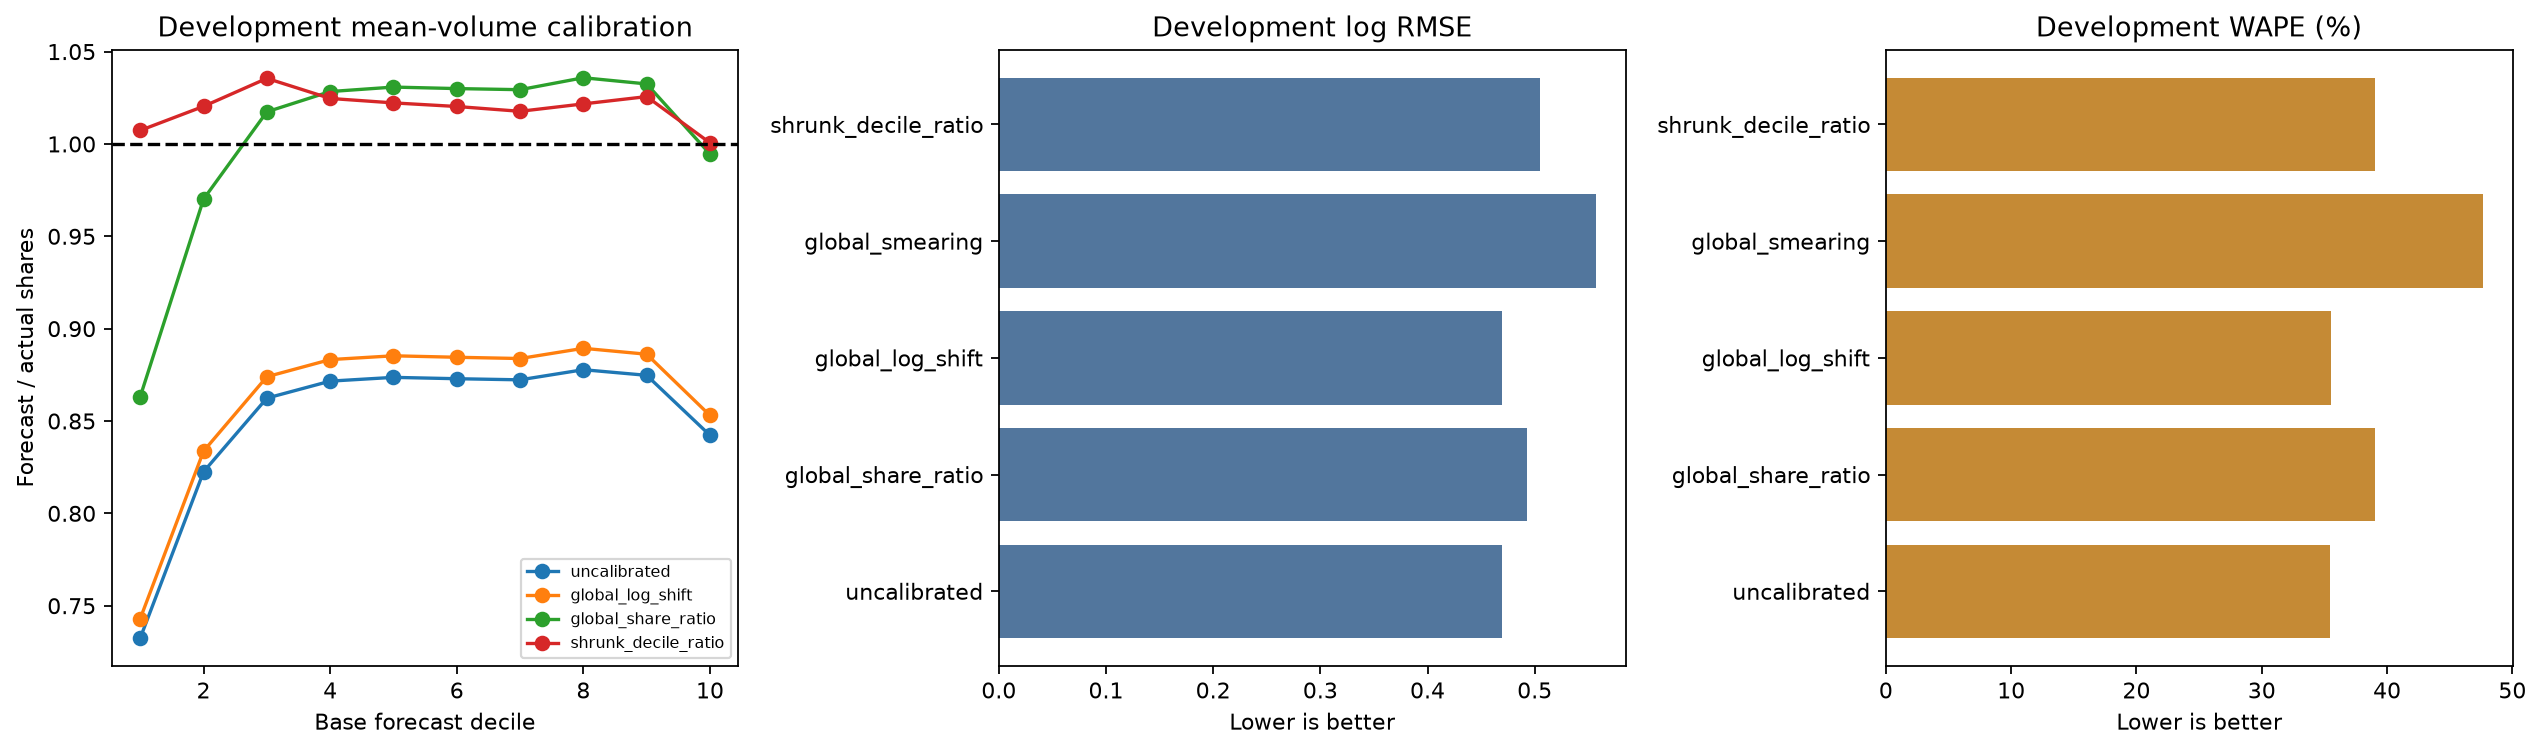

In [2]:
display(pd.read_csv(out / 'calibration_comparison.csv'))
display(Image(filename=str(out / 'calibration_comparison.png')))

In [3]:
display(pd.read_csv(out / 'error_concentration.csv'))
display(pd.read_csv(out / 'clipping_diagnostics.csv'))
display(pd.read_csv(out / 'segment_diagnostics.csv'))

,observations,total_absolute_share_error,top_1pct_error_rows_share_of_error,largest_actual_1pct_share_of_error,short_history_share_of_error
0,963525,7.643709e+10,0.356499,0.318169,0.002871


,test_year,rows,upper_clipped,lower_clipped,shares_removed_by_upper_bound,net_shares_removed_by_bounds,observed_base_shortfall
0,2022,328634,99,42,3.966406e+08,3.966405e+08,9.377767e+09
1,2023,318679,113,185,4.661942e+08,4.661937e+08,1.018148e+10
2,2024,316212,106,242,4.494417e+08,4.494397e+08,1.151715e+10
3,2025,307853,141,343,6.300294e+08,6.300016e+08,8.691265e+09


,method,dimension,segment,observations,mean_actual,mean_forecast,rmse_log,wape,aggregate_bias,mean_log_residual
0,uncalibrated,size,large,332056,4.405054e+05,3.878234e+05,0.396692,0.329197,-0.119594,0.007680
1,uncalibrated,size,small,291709,6.871829e+04,5.243286e+04,0.580040,0.446929,-0.236988,0.021783
2,uncalibrated,size,mid,339760,1.466678e+05,1.206718e+05,0.431512,0.387816,-0.177244,0.018612
3,uncalibrated,history,developing_5_19,2466,5.859823e+04,4.333435e+04,0.875143,0.460859,-0.260484,0.024950
4,uncalibrated,history,cold_0_4,758,2.350554e+05,8.052184e+04,1.509698,0.857964,-0.657435,0.256176
...,...,...,...,...,...,...,...,...,...,...
110,shrunk_decile_ratio,forecast_decile,7,96352,1.506375e+05,1.533006e+05,0.441743,0.362914,0.017678,-0.138039
111,shrunk_decile_ratio,forecast_decile,6,96352,1.052214e+05,1.073557e+05,0.443657,0.366277,0.020284,-0.143828
112,shrunk_decile_ratio,forecast_decile,9,96352,3.743346e+05,3.839329e+05,0.455434,0.374985,0.025641,-0.149992
113,shrunk_decile_ratio,actual_tail,lower_99pct,953888,1.782301e+05,1.981087e+05,0.498354,0.358672,0.111533,-0.181455


In [4]:
display(pd.read_csv(out / 'calibration_parameter_summary.csv'))
display(pd.read_csv(out / 'paired_bootstrap.csv'))
checks = pd.read_csv(out / 'validation_checks.csv')
assert checks.passed.all()
display(checks)

,test_year,fit_year,fit_rows,global_share_ratio,global_log_shift,global_smearing
0,2022,2021,321564,1.204069,0.002774,1.342315
1,2023,2022,328634,1.171824,0.010945,1.549807
2,2024,2023,318679,1.169624,0.022308,1.195318
3,2025,2024,316212,1.163429,0.014301,1.156978


,method,period,metric,dates,mean_difference,ci_2_5,ci_97_5
0,global_share_ratio,development,wape_delta,753,0.046694,0.043083,0.050091
1,global_share_ratio,development,log_mae_delta,753,0.037358,0.034066,0.040409
2,global_share_ratio,confirmation,wape_delta,250,0.053495,0.048596,0.058422
3,global_share_ratio,confirmation,log_mae_delta,250,0.044003,0.039760,0.048191
4,global_log_shift,development,wape_delta,753,0.001314,0.000999,0.001643
5,global_log_shift,development,log_mae_delta,753,0.000811,0.000505,0.001144
6,global_log_shift,confirmation,wape_delta,250,0.002680,0.002237,0.003141
7,global_log_shift,confirmation,log_mae_delta,250,0.002114,0.001682,0.002545
8,global_smearing,development,wape_delta,753,0.145021,0.136281,0.153889
9,global_smearing,development,log_mae_delta,753,0.111134,0.104317,0.118022


,check,passed
0,2022_calibration_is_prior_year,True
1,2022_row_order_and_labels,True
2,2022_saved_base_model_reconstructs_all_rows,True
3,2022_unclipped_diagnostic_finite,True
4,2022_uncalibrated_finite_nonnegative,True
...,...,...
82,2025_shrunk_decile_ratio_correction_replays,True
83,2025_shrunk_decile_ratio_metrics_recompute,True
84,historical_2021_model_fits_only_through_2020,True
85,historical_2021_complete_correct_evaluation_keys,True


In [5]:
display(pd.read_csv(out / 'largest_share_errors.csv').head(20))
display(pd.read_csv(out / 'date_error_summary.csv').head(20))

,date,permno,ticker,auction_volume,uncalibrated,base_abs_share_error,base_abs_log_error,prior_auction_observations,size_percentile,quarterly_options_expiry,monthly_options_expiry,is_last_trading_day_month,is_early_close,lag1_return,abnormal_volume_lag1,lag1_dividend_flag,lag1_distribution_flag,lag1_price_adjustment_flag,upper_clipped,lower_clipped
0,2024-09-20,19788,PLTR,205378788,7.615137e+06,1.977637e+08,3.294718,999,0.939274,True,True,False,False,0.012369,1.123937,False,False,False,True,False
1,2023-12-15,18576,UBER,191663779,6.931926e+06,1.847319e+08,3.319605,1159,0.968266,True,True,False,False,0.008553,1.448534,False,False,False,True,False
2,2023-08-24,23876,KVUE,178910438,4.502862e+06,1.744076e+08,3.682172,77,0.913897,False,False,False,False,-0.005055,2.139802,False,False,False,False,False
3,2022-09-30,13688,PCG,163370010,1.925352e+06,1.614447e+08,4.440908,1950,0.875000,False,False,True,False,-0.026730,1.559321,False,False,False,False,False
4,2023-03-17,60599,LUMN,147433401,6.931926e+06,1.405015e+08,3.057239,2065,0.474589,True,True,False,False,-0.038610,1.137358,False,False,False,True,False
5,2022-07-05,63765,SWN,112701929,1.657748e+06,1.110442e+08,4.219286,1887,0.713579,False,False,False,False,0.014400,0.780711,False,False,False,False,False
6,2024-07-19,18150,ETRN,98409026,5.621492e+05,9.784688e+07,5.165119,1426,0.577255,False,True,False,False,-0.007235,2.932320,False,False,False,False,False
7,2024-06-21,11990,KKR,78756997,2.248771e+06,7.650823e+07,3.555983,1501,0.954581,True,True,False,False,-0.003892,1.366383,False,False,False,False,False
8,2024-06-28,21102,DNA,77825757,4.433898e+06,7.339186e+07,2.865193,698,0.176977,False,False,True,False,0.089116,2.071514,False,False,False,False,False
9,2023-09-15,92108,BX,74192732,1.870321e+06,7.232241e+07,3.680555,1059,0.954476,True,True,False,False,-0.000355,1.311293,False,False,False,False,False


,date,stocks,actual_shares,forecast_shares,absolute_share_error,aggregate_bias,log_mae,monthly_expiry,quarterly_expiry,month_end,early_close
0,2022-06-24,1311,1.956359e+09,9.606294e+08,1.429689e+09,-0.508971,0.809690,0,0,0,0
1,2024-06-28,1264,2.063872e+09,7.310183e+08,1.376751e+09,-0.645803,0.848210,0,0,1,0
2,2024-09-20,1260,2.401480e+09,1.343067e+09,1.333042e+09,-0.440734,0.533063,1,1,0,0
3,2024-03-15,1265,2.271146e+09,1.457694e+09,1.301987e+09,-0.358168,0.572253,1,1,0,0
4,2023-03-17,1290,2.161868e+09,1.225190e+09,1.299981e+09,-0.433273,0.639999,1,1,0,0
5,2024-06-21,1267,2.087920e+09,1.211766e+09,1.135111e+09,-0.419630,0.586468,1,1,0,0
6,2023-12-15,1275,2.118113e+09,1.558343e+09,1.127411e+09,-0.264278,0.523229,1,1,0,0
7,2023-09-15,1284,1.965647e+09,1.322320e+09,1.080238e+09,-0.327285,0.558275,1,1,0,0
8,2024-12-20,1251,2.227124e+09,1.542207e+09,1.038348e+09,-0.307534,0.482026,1,1,0,0
9,2023-06-23,1278,1.483822e+09,9.456360e+08,9.600061e+08,-0.362703,0.724829,0,0,0,0
